In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time
import os
import warnings
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, 
                           roc_auc_score, classification_report, confusion_matrix, roc_curve)
import pickle

warnings.filterwarnings('ignore')
plt.rcParams['font.size'] = 12
plt.rcParams['figure.figsize'] = (10, 6)
PLOTS_DIR = "../static/plots"
os.makedirs(PLOTS_DIR, exist_ok=True)
np.random.seed(42)

Rozmiar zbioru: (88647, 112)
Liczba cech: 111

Pierwsze 5 kolumn: ['qty_dot_url', 'qty_hyphen_url', 'qty_underline_url', 'qty_slash_url', 'qty_questionmark_url']
Ostatnie 5 kolumn: ['qty_redirects', 'url_google_index', 'domain_google_index', 'url_shortened', 'phishing']

Rozkład etykiet:
URL oznaczone jako bezpieczne: 58,000 (65.4%)
URL oznaczone jako phisingowe: 30,647 (34.6%)


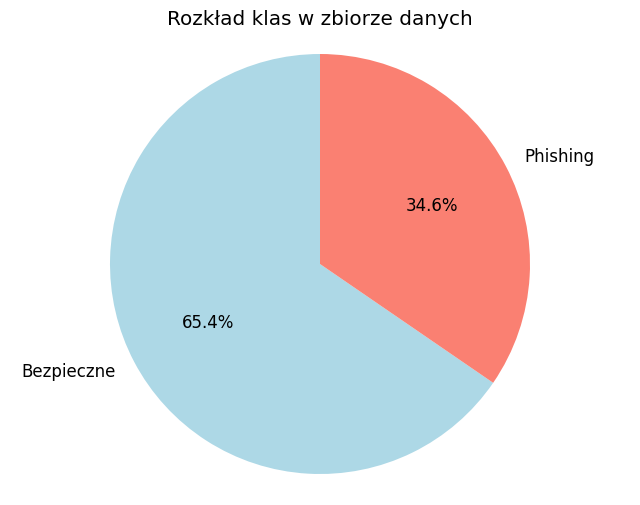


Informacje o zbiorze:
- Łączna liczba próbek: 88,647
- Liczba cech: 111
- Brakujące wartości: 0
- Duplikaty: 1438

Dostępne cechy: 100
Przykładowe cechy: ['qty_dot_url', 'qty_hyphen_url', 'qty_underline_url', 'qty_slash_url', 'qty_questionmark_url', 'qty_equal_url', 'qty_at_url', 'qty_and_url', 'qty_exclamation_url', 'qty_space_url']


In [7]:
df = pd.read_csv('../data/dataset_full.csv')

print(f"Rozmiar zbioru: {df.shape}")
print(f"Liczba cech: {len(df.columns)-1}")

print(f"\nPierwsze 5 kolumn: {list(df.columns[:5])}")
print(f"Ostatnie 5 kolumn: {list(df.columns[-5:])}")

label_counts = df['phishing'].value_counts()
print(f"\nRozkład etykiet:")
print(f"URL oznaczone jako bezpieczne: {label_counts[0]:,} ({label_counts[0]/len(df)*100:.1f}%)")
print(f"URL oznaczone jako phisingowe: {label_counts[1]:,} ({label_counts[1]/len(df)*100:.1f}%)")

plt.figure(figsize=(8, 6))
colors = ['lightblue', 'salmon']
labels = ['Bezpieczne', 'Phishing']
plt.pie(label_counts.values, labels=labels, colors=colors, autopct='%1.1f%%', startangle=90)
plt.title('Rozkład klas w zbiorze danych')
plt.axis('equal')
plt.show()

print(f"\nInformacje o zbiorze:")
print(f"- Łączna liczba próbek: {len(df):,}")
print(f"- Liczba cech: {len(df.columns)-1}")
print(f"- Brakujące wartości: {df.isnull().sum().sum()}")
print(f"- Duplikaty: {df.duplicated().sum()}")

# Wszystkie kolumny oprócz kolumny docelowej 'phishing' to cechy
network_dependent_features = [
    'time_response', 'domain_spf', 'asn_ip', 'time_domain_activation', 
    'time_domain_expiration', 'qty_ip_resolved', 'qty_nameservers', 
    'qty_mx_servers', 'ttl_hostname', 'url_google_index', 'domain_google_index'
]
feature_columns = [col for col in df.columns if col != 'phishing' and col not in network_dependent_features]
print(f"\nDostępne cechy: {len(feature_columns)}")
print(f"Przykładowe cechy: {feature_columns[:10]}")

In [8]:
network_dependent_features = [
    'time_response', 'domain_spf', 'asn_ip', 'time_domain_activation', 
    'time_domain_expiration', 'qty_ip_resolved', 'qty_nameservers', 
    'qty_mx_servers', 'ttl_hostname', 'url_google_index', 'domain_google_index'
]

feature_columns = [col for col in df.columns if col != 'phishing' and col not in network_dependent_features]
X = df[feature_columns]
y = df['phishing']

print(f"\nLista cech ({len(feature_columns)}):")
for i, col in enumerate(feature_columns[:20], 1):
    print(f"{i:2d}. {col}")
if len(feature_columns) > 20:
    print(f"... i {len(feature_columns)-20} więcej")

print(f"\nRozkład etykiet:")
for label, count in y.value_counts().items():
    percentage = count / len(y) * 100
    label_name = "Brak phishingu" if label == 0 else "Phishing"
    print(f"  {label} ({label_name}): {count:,} ({percentage:.1f}%)")

print(f"\nTypy danych:")
data_types = X.dtypes.value_counts()
for dtype, count in data_types.items():
    print(f"  {dtype}: {count} kolumn")

inf_count = np.isinf(X.values).sum()
nan_count = X.isnull().sum().sum()

print(f"  Wartości nieskończone: {inf_count}")
print(f"  Brakujące wartości: {nan_count}")

if inf_count > 0:
    print("Zastępowanie wartości nieskończonych medianą...")
    X = X.replace([np.inf, -np.inf], np.nan)

if X.isnull().sum().sum() > 0:
    print("Wypełnianie brakujących wartości medianą...")
    X = X.fillna(X.median())


Lista cech (100):


 1. qty_dot_url
 2. qty_hyphen_url
 3. qty_underline_url
 4. qty_slash_url
 5. qty_questionmark_url
 6. qty_equal_url
 7. qty_at_url
 8. qty_and_url
 9. qty_exclamation_url
10. qty_space_url
11. qty_tilde_url
12. qty_comma_url
13. qty_plus_url
14. qty_asterisk_url
15. qty_hashtag_url
16. qty_dollar_url
17. qty_percent_url
18. qty_tld_url
19. length_url
20. qty_dot_domain
... i 80 więcej

Rozkład etykiet:
  0 (Brak phishingu): 58,000 (65.4%)
  1 (Phishing): 30,647 (34.6%)

Typy danych:
  int64: 100 kolumn
  Wartości nieskończone: 0
  Brakujące wartości: 0


In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(f"Zbiór uczący: {X_train.shape[0]:,} próbek ({X_train.shape[0]/len(X)*100:.1f}%)")
print(f"Zbiór testowy: {X_test.shape[0]:,} próbek ({X_test.shape[0]/len(X)*100:.1f}%)")

print(f"\nRozkład klas w zbiorze uczącym:")
train_counts = y_train.value_counts()
print(f"  Brak phishingu: {train_counts[0]:,} ({train_counts[0]/len(y_train)*100:.1f}%)")
print(f"  Phishing: {train_counts[1]:,} ({train_counts[1]/len(y_train)*100:.1f}%)")

print(f"\nRozkład klas w zbiorze testowym:")
test_counts = y_test.value_counts()
print(f"  Brak phishingu: {test_counts[0]:,} ({test_counts[0]/len(y_test)*100:.1f}%)")
print(f"  Phishing: {test_counts[1]:,} ({test_counts[1]/len(y_test)*100:.1f}%)")

Zbiór uczący: 70,917 próbek (80.0%)
Zbiór testowy: 17,730 próbek (20.0%)

Rozkład klas w zbiorze uczącym:
  Brak phishingu: 46,400 (65.4%)
  Phishing: 24,517 (34.6%)

Rozkład klas w zbiorze testowym:
  Brak phishingu: 11,600 (65.4%)
  Phishing: 6,130 (34.6%)


In [10]:
param_grids = [
    {
        'name': 'Podstawowe parametry',
        'params': {
            'n_estimators': [50, 100, 200],
            'max_depth': [10, 20, None],
            'min_samples_split': [2, 5, 10],
            'min_samples_leaf': [1, 2, 4]
        }
    },
    {
        'name': 'Zaawansowane parametry',
        'params': {
            'n_estimators': [200, 300, 500],
            'max_depth': [15, 25, None],
            'min_samples_split': [2, 3, 5],
            'min_samples_leaf': [1, 2, 3],
            'max_features': ['sqrt', 'log2']
        }
    },
    {
        'name': 'Optymalizacja dokładności',
        'params': {
            'n_estimators': [500, 700, 1000],
            'max_depth': [20, 30, None],
            'min_samples_split': [2, 3, 4],
            'min_samples_leaf': [1, 2],
            'max_features': ['sqrt', 'log2'],
            'bootstrap': [True, False]
        }
    }
]

best_overall_score = 0
best_overall_model = None
best_overall_params = None
best_config_name = ""

start_time = time.time()

for i, grid_config in enumerate(param_grids):
    config_name = grid_config['name']
    param_grid = grid_config['params']
    
    print(f"\n--- Konfiguracja {i+1}/{len(param_grids)}: {config_name} ---")
    
    combinations = 1
    for param_values in param_grid.values():
        combinations *= len(param_values)
    print(f"Testowanie {combinations} kombinacji...")
    
    grid_start_time = time.time()
    
    grid_search = GridSearchCV(
        RandomForestClassifier(random_state=42, n_jobs=-1),
        param_grid,
        cv=3,
        scoring='roc_auc',
        n_jobs=-1,
        verbose=0
    )
    
    grid_search.fit(X_train, y_train)
    grid_time = time.time() - grid_start_time
    
    print(f"Czas wykonania: {grid_time:.2f} sekund")
    print(f"Najlepszy CV ROC-AUC: {grid_search.best_score_:.4f}")
    print(f"Najlepsze parametry: {grid_search.best_params_}")
    
    if grid_search.best_score_ > best_overall_score:
        best_overall_score = grid_search.best_score_
        best_overall_model = grid_search.best_estimator_
        best_overall_params = grid_search.best_params_
        best_config_name = config_name
        print(f"Nowy najlepszy model z konfiguracji: {config_name}")

total_time = time.time() - start_time
best_model = best_overall_model

print(f"Całkowity czas strojenia: {total_time:.2f} sekund ({total_time/60:.1f} minut)")
print(f"Najlepszy CV ROC-AUC: {best_overall_score:.4f}")
print(f"Najlepsza konfiguracja: {best_config_name}")
print(f"Najlepsze parametry:")
for param, value in best_overall_params.items():
    print(f"   {param}: {value}")

if best_overall_score >= 0.95:
    print("Doskonała wydajność CV (≥95%)")
elif best_overall_score >= 0.90:
    print("Bardzo dobra wydajność CV (≥90%)")
elif best_overall_score >= 0.85:
    print("Dobra wydajność CV (≥85%)")
else:
    print("Wydajność CV wymaga poprawy (<85%)")


--- Konfiguracja 1/3: Podstawowe parametry ---
Testowanie 81 kombinacji...
Czas wykonania: 197.53 sekund
Najlepszy CV ROC-AUC: 0.9819
Najlepsze parametry: {'max_depth': None, 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 200}
Nowy najlepszy model z konfiguracji: Podstawowe parametry

--- Konfiguracja 2/3: Zaawansowane parametry ---
Testowanie 162 kombinacji...
Czas wykonania: 197.53 sekund
Najlepszy CV ROC-AUC: 0.9819
Najlepsze parametry: {'max_depth': None, 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 200}
Nowy najlepszy model z konfiguracji: Podstawowe parametry

--- Konfiguracja 2/3: Zaawansowane parametry ---
Testowanie 162 kombinacji...
Czas wykonania: 946.57 sekund
Najlepszy CV ROC-AUC: 0.9819
Najlepsze parametry: {'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 500}
Nowy najlepszy model z konfiguracji: Zaawansowane parametry

--- Konfiguracja 3/3: Optymalizacja dokładności ---
Testowani

Generowanie predykcji...
Wykonywanie walidacji krzyżowej...
Wykonywanie walidacji krzyżowej...

METRYKI WYDAJNOŚCI
Dokładność:     0.9418 (94.18%)
Precyzja:       0.9229 (92.29%)
Czułość:        0.9075 (90.75%)
Miara F1:       0.9151
ROC-AUC:        0.9833
CV ROC-AUC:     0.9829 (±0.0012)
                    precision    recall  f1-score   support

Bez phisingowe URL       0.95      0.96      0.96     11600
   Phishingowe URL       0.92      0.91      0.92      6130

          accuracy                           0.94     17730
         macro avg       0.94      0.93      0.94     17730
      weighted avg       0.94      0.94      0.94     17730


Macierz pomyłek:
  Prawdziwie negatywne (TN): 11,135
  Fałszywie pozytywne (FP): 465
  Fałszywie negatywne (FN): 567
  Prawdziwie pozytywne (TP): 5,563

10 najważniejszych cech:
   1. directory_length: 0.0989
   2. qty_slash_url: 0.0499
   3. length_url: 0.0412
   4. file_length: 0.0367
   5. qty_slash_directory: 0.0362
   6. qty_equal_director

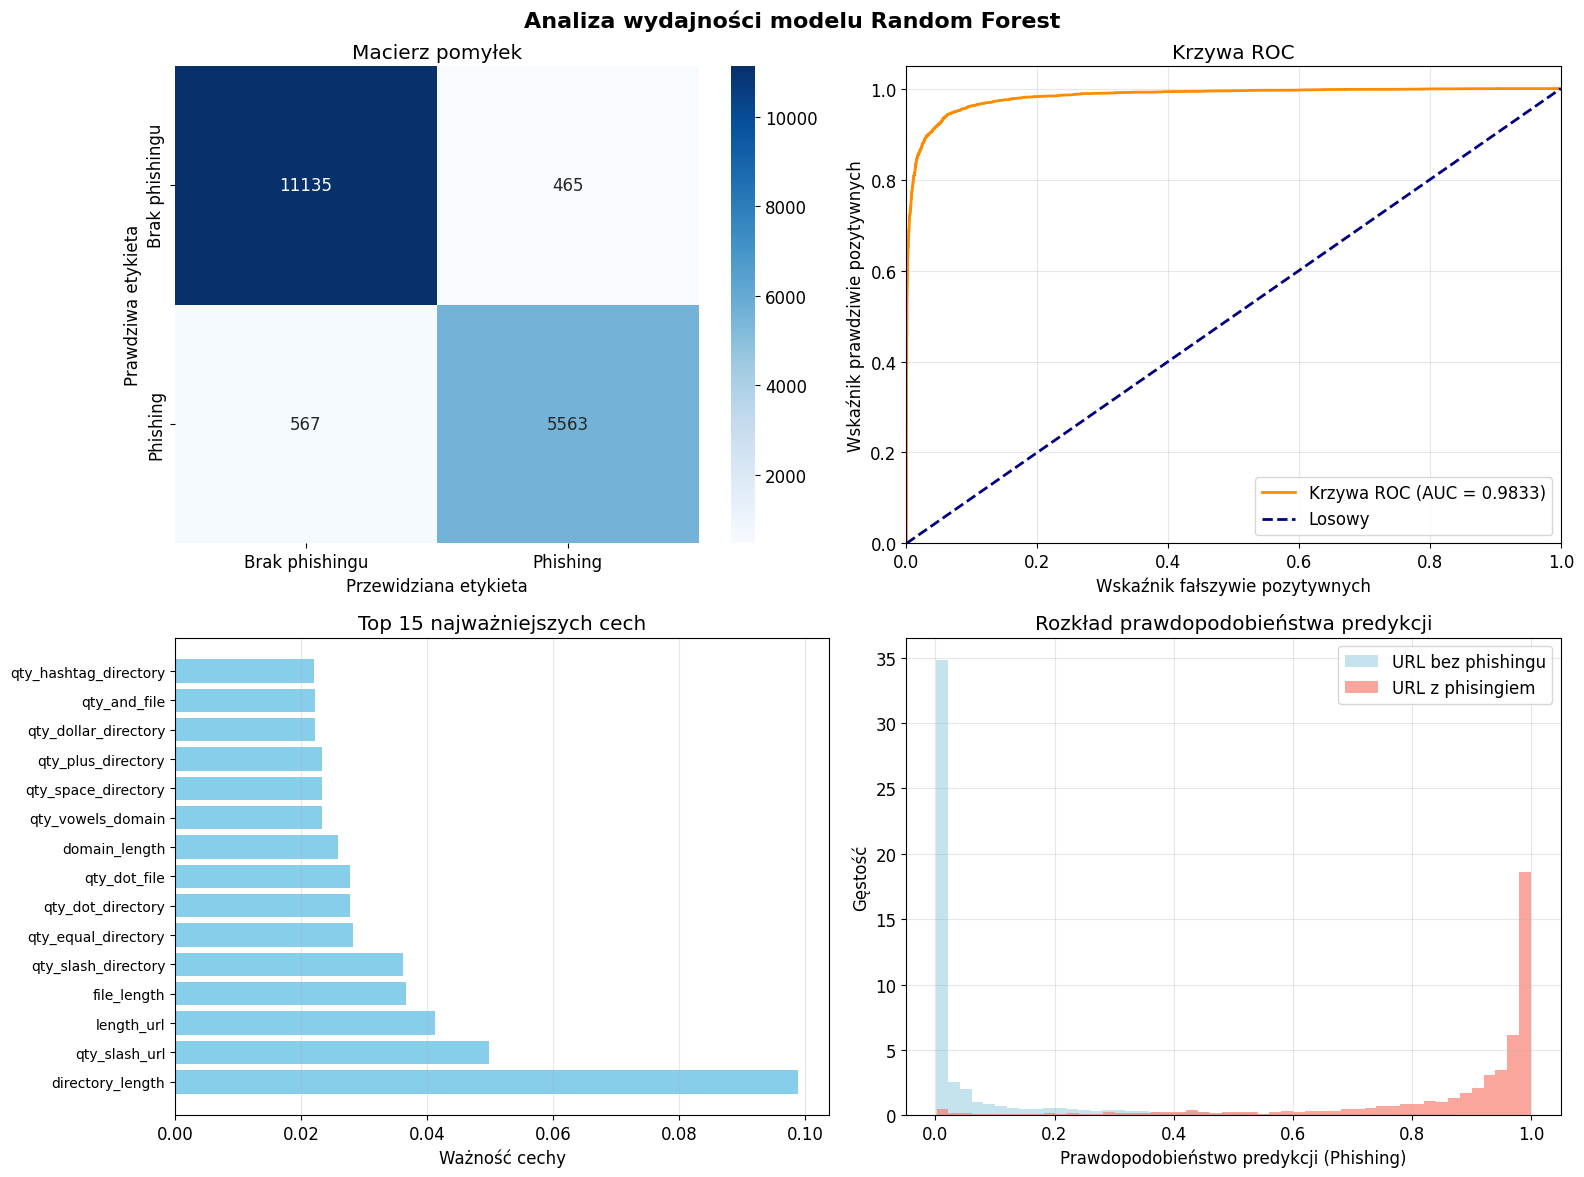


KOŃCOWA OCENA MODELU
Wydajność modelu: BARDZO DOBRY


In [11]:
print("Generowanie predykcji...")
y_pred = best_model.predict(X_test)
y_pred_proba = best_model.predict_proba(X_test)[:, 1]

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
auc_roc = roc_auc_score(y_test, y_pred_proba)

print("Wykonywanie walidacji krzyżowej...")
cv_scores = cross_val_score(best_model, X_train, y_train, cv=5, scoring='roc_auc')

print("\n" + "="*50)
print("METRYKI WYDAJNOŚCI")
print("="*50)
print(f"Dokładność:     {accuracy:.4f} ({accuracy*100:.2f}%)")
print(f"Precyzja:       {precision:.4f} ({precision*100:.2f}%)")
print(f"Czułość:        {recall:.4f} ({recall*100:.2f}%)")
print(f"Miara F1:       {f1:.4f}")
print(f"ROC-AUC:        {auc_roc:.4f}")
print(f"CV ROC-AUC:     {cv_scores.mean():.4f} (±{cv_scores.std()*2:.4f})")

target_names = ['Bez phisingowe URL', 'Phishingowe URL']
print(classification_report(y_test, y_pred, target_names=target_names))

cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()

print(f"\nMacierz pomyłek:")
print(f"  Prawdziwie negatywne (TN): {tn:,}")
print(f"  Fałszywie pozytywne (FP): {fp:,}")
print(f"  Fałszywie negatywne (FN): {fn:,}")
print(f"  Prawdziwie pozytywne (TP): {tp:,}")

feature_importance = pd.DataFrame({
    'feature': X.columns,
    'importance': best_model.feature_importances_
}).sort_values('importance', ascending=False)

print(f"\n10 najważniejszych cech:")
for i, (_, row) in enumerate(feature_importance.head(10).iterrows(), 1):
    print(f"  {i:2d}. {row['feature']}: {row['importance']:.4f}")

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('Analiza wydajności modelu Random Forest', fontsize=16, fontweight='bold')

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Brak phishingu', 'Phishing'], 
            yticklabels=['Brak phishingu', 'Phishing'], 
            ax=axes[0,0])
axes[0,0].set_title('Macierz pomyłek')
axes[0,0].set_ylabel('Prawdziwa etykieta')
axes[0,0].set_xlabel('Przewidziana etykieta')

fpr, tpr, _ = roc_curve(y_test, y_pred_proba)
axes[0,1].plot(fpr, tpr, color='darkorange', lw=2, 
               label=f'Krzywa ROC (AUC = {auc_roc:.4f})')
axes[0,1].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', 
               label='Losowy')
axes[0,1].set_xlim([0.0, 1.0])
axes[0,1].set_ylim([0.0, 1.05])
axes[0,1].set_xlabel('Wskaźnik fałszywie pozytywnych')
axes[0,1].set_ylabel('Wskaźnik prawdziwie pozytywnych')
axes[0,1].set_title('Krzywa ROC')
axes[0,1].legend(loc="lower right")
axes[0,1].grid(True, alpha=0.3)

top_features = feature_importance.head(15)
axes[1,0].barh(range(len(top_features)), top_features['importance'], color='skyblue')
axes[1,0].set_yticks(range(len(top_features)))
axes[1,0].set_yticklabels(top_features['feature'], fontsize=10)
axes[1,0].set_xlabel('Ważność cechy')
axes[1,0].set_title('Top 15 najważniejszych cech')
axes[1,0].grid(True, alpha=0.3, axis='x')

axes[1,1].hist(y_pred_proba[y_test == 0], bins=50, alpha=0.7, 
               label='URL bez phishingu', color='lightblue', density=True)
axes[1,1].hist(y_pred_proba[y_test == 1], bins=50, alpha=0.7, 
               label='URL z phisingiem', color='salmon', density=True)
axes[1,1].set_xlabel('Prawdopodobieństwo predykcji (Phishing)')
axes[1,1].set_ylabel('Gęstość')
axes[1,1].set_title('Rozkład prawdopodobieństwa predykcji')
axes[1,1].legend()
axes[1,1].grid(True, alpha=0.3)

plt.tight_layout()

plot_filename = f"{PLOTS_DIR}/random_forest_analysis.png"
plt.savefig(plot_filename, dpi=300, bbox_inches='tight')

plt.show()

print(f"\n{'='*50}")
print(f"KOŃCOWA OCENA MODELU")
print(f"{'='*50}")

high_performance_metrics = [
    accuracy >= 0.95, 
    precision >= 0.95, 
    recall >= 0.95, 
    f1 >= 0.95, 
    auc_roc >= 0.95
]

if all(high_performance_metrics):
    performance_level = "DOSKONAŁY"
elif accuracy >= 0.90 and auc_roc >= 0.90:
    performance_level = "BARDZO DOBRY"
elif accuracy >= 0.85 and auc_roc >= 0.85:
    performance_level = "DOBRY"
else:
    performance_level = "WYMAGA POPRAWY"

print(f"Wydajność modelu: {performance_level}")



In [12]:
os.makedirs('../models', exist_ok=True)
os.makedirs('../data', exist_ok=True)

model_data = {
    'model': best_model,
    'scaler': None,
    'feature_names': X.columns.tolist(),
    'best_params': best_overall_params,
    'metrics': {
        'accuracy': accuracy,
        'precision': precision,
        'recall': recall,
        'f1': f1,
        'auc_roc': auc_roc,
        'cv_auc_mean': cv_scores.mean(),
        'cv_auc_std': cv_scores.std()
    }
}

model_path = '../models/random_forest_model.pkl'
with open(model_path, 'wb') as f:
    pickle.dump(model_data, f)

results_df = pd.DataFrame({
    'Metryka': ['Dokładność', 'Precyzja', 'Czułość', 'Miara F1', 'AUC-ROC'],
    'Wartość': [accuracy, precision, recall, f1, auc_roc]
})

results_path = '../data/random_forest_results.csv'
results_df.to_csv(results_path, index=False)

performance_summary = {
    'typ_modelu': 'Random Forest',
    'dokładność': accuracy,
    'precyzja': precision,
    'czułość': recall,
    'miara_f1': f1,
    'roc_auc': auc_roc,
    'cv_auc_średnia': cv_scores.mean(),
    'cv_auc_odchylenie': cv_scores.std(),
    'liczba_cech': len(X.columns),
    'próbki_uczące': len(X_train),
    'próbki_testowe': len(X_test),
    'czas_strojenia': total_time,
    'najlepsza_konfiguracja': best_config_name
}

for key, value in performance_summary.items():
    if isinstance(value, float):
        print(f"{key.replace('_', ' ').title()}: {value:.4f}")
    else:
        print(f"{key.replace('_', ' ').title()}: {value}")

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Brak phishingu', 'Phishing'], 
            yticklabels=['Brak phishingu', 'Phishing'])
plt.title('Macierz pomyłek - Random Forest')
plt.ylabel('Prawdziwa etykieta')
plt.xlabel('Przewidziana etykieta')
plt.savefig(f'{PLOTS_DIR}/random_forest_confusion_matrix.png', dpi=300, bbox_inches='tight')
plt.close()

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'Krzywa ROC (AUC = {auc_roc:.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Wskaźnik fałszywie pozytywnych')
plt.ylabel('Wskaźnik prawdziwie pozytywnych')
plt.title('Krzywa ROC - Random Forest')
plt.legend(loc="lower right")
plt.savefig(f'{PLOTS_DIR}/random_forest_roc_curve.png', dpi=300, bbox_inches='tight')
plt.close()

Typ Modelu: Random Forest
Dokładność: 0.9418
Precyzja: 0.9229
Czułość: 0.9075
Miara F1: 0.9151
Roc Auc: 0.9833
Cv Auc Średnia: 0.9829
Cv Auc Odchylenie: 0.0006
Liczba Cech: 100
Próbki Uczące: 70917
Próbki Testowe: 17730
Czas Strojenia: 4234.5921
Najlepsza Konfiguracja: Optymalizacja dokładności
